In [1]:
import sys

sys.path.append("../src")
from configs.load_config import load_config
from data_processing.load import load_dataset
from models.build import build_model
from training.train import train_torch, sample_numpyro
import importlib
import training.evaluate as load_eval

importlib.reload(load_eval)
import matplotlib.pyplot as plt
from training.evaluate import (
    evaluate_model,
    evaluate_numpyro,
    evaluate_numpyro_on_train_set,
)
import importlib
import training.plot as load_plot

importlib.reload(load_plot)
from training.plot import (
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_residuals,
    plot_qr_hdi_prediction,
    plot_quantile_calibration,
    plot_first_layer_feature_posteriors,
    plot_bnn_weight_posteriors,
    plot_posterior_predictive_vs_likelihood,
    plot_stacked_hdi_intervals,
    plot_pit_histogram,
    extract_quantile_curves,
    evaluate_and_plot_qr_ensemble_medians,
    plot_posterior_predictive_family,
    plot_qr_hdi_prediction_ensemble,
    plot_qr_hdi_prediction_ensemble_outline,
    plot_qr_hdi_prediction_ensemble_std,
    plot_qr_hdi_prediction_ensemble_std_bands,
    plot_bnn_gamma_combined,
)
import torch
import numpy as np
import numpyro
from data_processing.utils import (
    load_torch_model,
    load_checkpoint,
    save_scaler_params,
    approximate_qr_intervals,
)
import pandas as pd
from types import SimpleNamespace

In [54]:
# model_cfg = load_config("../configs/model/torch_model_quantile.yaml")
# file_name = "WindPowerQuantile_weighted_2026-03-16_12-38-33_nowcast_gen_ELSPOT_NO1"
# data_cfg = load_config(model_cfg.data.path)

model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted_150.yaml")
data_cfg = load_config(model_cfg.data.path)
file_name = "model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3"

# model_cfg = load_config("../configs/model/bnn_gen_model_nowcast_03_weighted.yaml")
# data_cfg = load_config(model_cfg.data.path)
# file_name = "model_mw_gamma_extended_2026-02-16_15-32-06_nowcast_ELSPOT_NO3"  # "model_mw_gamma_extended_2026-02-16_11-27-43_nowcast_ELSPOT_NO1"

In [55]:
data_cfg.dataset = "forecast"
data_cfg.ensemble = SimpleNamespace(members=None, variance=False)

In [70]:
data = load_dataset(data_cfg)

Loading forecast data for ELSPOT NO3, ensemble members [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14]...
Loaded scaler parameters for ELSPOT NO3 and nowcast
  Saved at: 2026-03-20 10:19:42
  Split time: 2025-01-01 00:00:00+01:00
Dropping 15 gust columns not present in nowcast

Column mapping summary:
  Original columns: 94
  Renamed columns: 79
  Dropped columns: 15
  Final columns: 79

 Index([      0,       1,       2,       3,       4,       5,       6,       7,
             8,       9,
       ...
       6874202, 6874203, 6874204, 6874205, 6874206, 6874207, 6874208, 6874209,
       6874210, 6874211],
      dtype='int64', length=6761520)
All parks operational from 2022-10-12 12:00:00
Before 2-day ahead filtering: 1316376 rows
After 2-day ahead filtering: 489192 rows
Lead time range: 34.0h to 61.0h


/Users/noemiweber/Documents/Studium/master/4.semester_norway/WindAIcompetition/notebooks/../src/data_processing/downtime.py:64: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  maintenance_events.drop(


Maintenance hours in operational period: 451
Preprocessing done. X_train shape: (18069, 24, 15, 10)
Preprocessing done. X_test shape: (1895, 24, 15, 10)


In [5]:
Y_train = data["Y_train_gen"]

In [6]:
# from data_processing.synthetic_data import synthetic_power_data

max_scaling = 1
# data["Y_train_gen"], _ = synthetic_power_data(data, "X_train")
# data["Y_test_gen"], _ = synthetic_power_data(data, "X_test")

# data["Y_train_gen"] /= max_scaling
# data["Y_test_gen"] /= max_scaling

In [7]:
data["Y_train_gen"].min(), data["Y_train_gen"].max()

(np.float32(1.6830666), np.float32(1921.0524))

In [8]:
if data_cfg.dataset == "nowcast":
    save_scaler_params(
        scaler_params=data["scaler_params"],
        site_scaler_params=data["site_scaler_params"],
        bid_zone=data_cfg.bid_zone,
        split_time=pd.Timestamp("2025-01-01 00:00:00", tz="CET"),
        dataset=data_cfg.dataset,
        dir_path="../checkpoints",
    )

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl


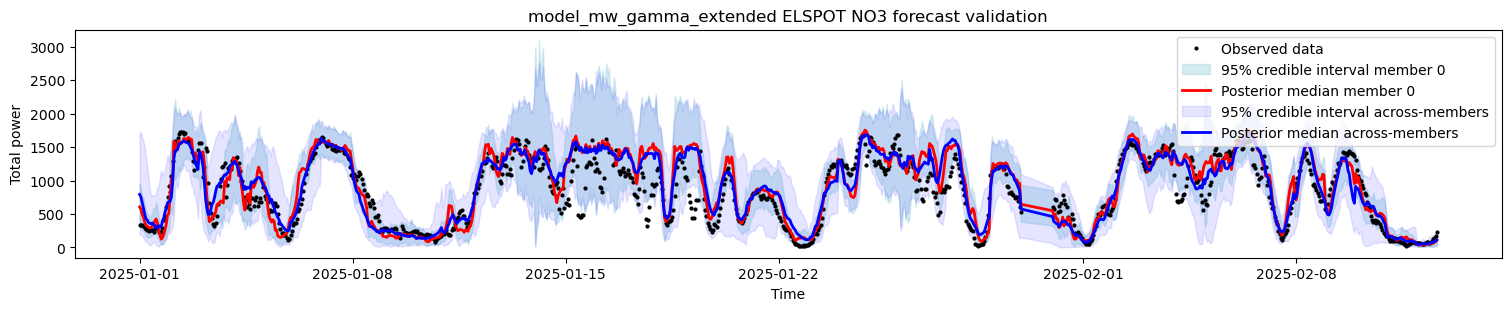

In [9]:
if model_cfg.backend == "numpyro":
    checkpoint = load_checkpoint(file_name=file_name)
    model = build_model(checkpoint["model_cfg"], data)

    plot_bnn_gamma_combined(
        checkpoint,
        model,
        data,
        data_cfg,
        1000,
    )
    plt.show()

In [10]:
median_list = []
hdi_list = []
percentile_list = []
y_pred_list = []

for member in range(15):

    if model_cfg.backend == "torch":
        # Quantiles
        if model_cfg.params.quantiles is None:
            quantiles = torch.linspace(0, 1, 51)
        else:
            quantiles = torch.tensor(model_cfg.params.quantiles)
        model, checkpoint = load_torch_model(file_name=file_name, quantiles=quantiles)

        metrics, y_pred = evaluate_model(
            model=model,
            data=data,
            quantiles=quantiles,
            model_cfg=checkpoint["model_cfg"],
            member=member,
        )

        hdis, _, _, _ = approximate_qr_intervals(
            Y_pred=y_pred,
            taus=quantiles,
            cred_mass=0.95,
        )

        # Extract curves, TODO: not 95% CI!!
        median, lower, upper = extract_quantile_curves(
            Y_pred_quantiles=y_pred,
            quantiles=quantiles,
            median_q=0.5,
            lower_q=0.02,
            upper_q=0.98,
        )

        percentiles = np.stack([lower, upper], axis=1)

        median_list.append(median)
        hdi_list.append(hdis.T)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    elif model_cfg.backend == "numpyro":

        checkpoint = load_checkpoint(file_name=file_name)
        model = build_model(checkpoint["model_cfg"], data)
        samples = checkpoint["samples"]
        metrics, y_pred, predictive, median, percentiles, hdis = evaluate_numpyro(
            model=model,
            samples=checkpoint["samples"],
            rng_key_predict=checkpoint["rng_key_predict"],
            data=data,
            model_cfg=checkpoint["model_cfg"],
            member=member,
            max_scaling=max_scaling,
        )
        if member == 0:
            print(metrics)

        median_list.append(median)
        hdi_list.append(hdis)
        percentile_list.append(percentiles)
        y_pred_list.append(y_pred)

    # print(metrics)

    if data_cfg.dataset == "nowcast":
        # validate on nowcast, only one loop, otherwise validation on all ensemble members
        print("break")
        break


# assert checkpoint["model_cfg"] == model_cfg

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
test max 7.297114 1750.2035
train max 1.6830666 1921.0524
RMSE train: 252.43073
CRPS train:  132.4466697875329
RMSE val: 257.1786
CRPS val:  140.25815990973868 

{'rmse_median': np.float32(257.1786), 'coverage_025_975': np.float64(0.7715039577836411), 'coverage_0_50': np.float64(0.6163588390501319), 'crps': np.float64(140.25815990973868)}
Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
test max 7.297114 1750.2035
train max 1.6830666 1921.0524
RMSE train: 297.9397
CRPS train:  163.0853540792527
RMSE val: 294.43655
CRPS val:  165.61985494349935 

Loading specified checkpoint: ../checkpoints/model_mw_gamma_extended_2026-03-27_06-31-31_nowcast_ELSPOT_NO3.pkl
test max 7.297114 1750.2035
train max 1.6830666 1921.0524
RMSE train: 290.98337
CRPS train:  157.8771220933503
RMSE val: 299.75464
CRPS val:  170.1597840640922 


In [11]:
median_df = pd.DataFrame(
    np.column_stack(median_list),
    columns=[f"median_{i}" for i in range(len(median_list))],
)

hdi_dict = {}

for i, arr in enumerate(hdi_list):
    hdi_dict[f"hdi_lower_{i}"] = arr[0]
    hdi_dict[f"hdi_upper_{i}"] = arr[1]

hdi_df = pd.DataFrame(hdi_dict)

ensemble_results = pd.concat([median_df, hdi_df], axis=1)

median_cols = ensemble_results.filter(regex=r"^median_").columns
hdi_lower_cols = ensemble_results.filter(regex=r"^hdi_lower_").columns
hdi_upper_cols = ensemble_results.filter(regex=r"^hdi_upper_").columns

ensemble_results["mean_median"] = ensemble_results[median_cols].mean(axis=1)
ensemble_results["std_median"] = ensemble_results[median_cols].std(axis=1)
ensemble_results["mean_hdi_lower"] = ensemble_results[hdi_lower_cols].mean(axis=1)
ensemble_results["std_hdi_lower"] = ensemble_results[hdi_lower_cols].std(axis=1)
ensemble_results["mean_hdi_upper"] = ensemble_results[hdi_upper_cols].mean(axis=1)
ensemble_results["std_hdi_upper"] = ensemble_results[hdi_upper_cols].std(axis=1)

In [12]:
# import numpy as np

# for k, v in samples.items():
#     v = np.asarray(v)
#     print(
#         f"{k:20s} shape={v.shape} finite={np.isfinite(v).all()} "
#         f"min={np.nanmin(v):.3g} max={np.nanmax(v):.3g}"
#     )

In [13]:
# import numpy as np
# import arviz as az

# posterior = {k: np.asarray(v)[None, ...] for k, v in samples.items()}  # (1, 100, ...)

# idata = az.from_dict(posterior=posterior)
# az.plot_trace(idata, var_names=["b1", "b2", "b3mu", "b3k"])

In [14]:
# import matplotlib.pyplot as plt

# i = 0
# plt.plot(samples["mu"][:, i])
# plt.title(f"Trace mu[{i}]")
# plt.show()

### Plots


In [15]:
if model_cfg.backend == "numpyro":
    X_test = data["X_test"]
    if len(X_test.shape) == 4:
        X_test = X_test[:, :, 0]
    graph = numpyro.render_model(
        model,
        model_args=(X_test,),
    )
    graph

In [16]:
try:
    graph
except:
    pass

(200, 18069)


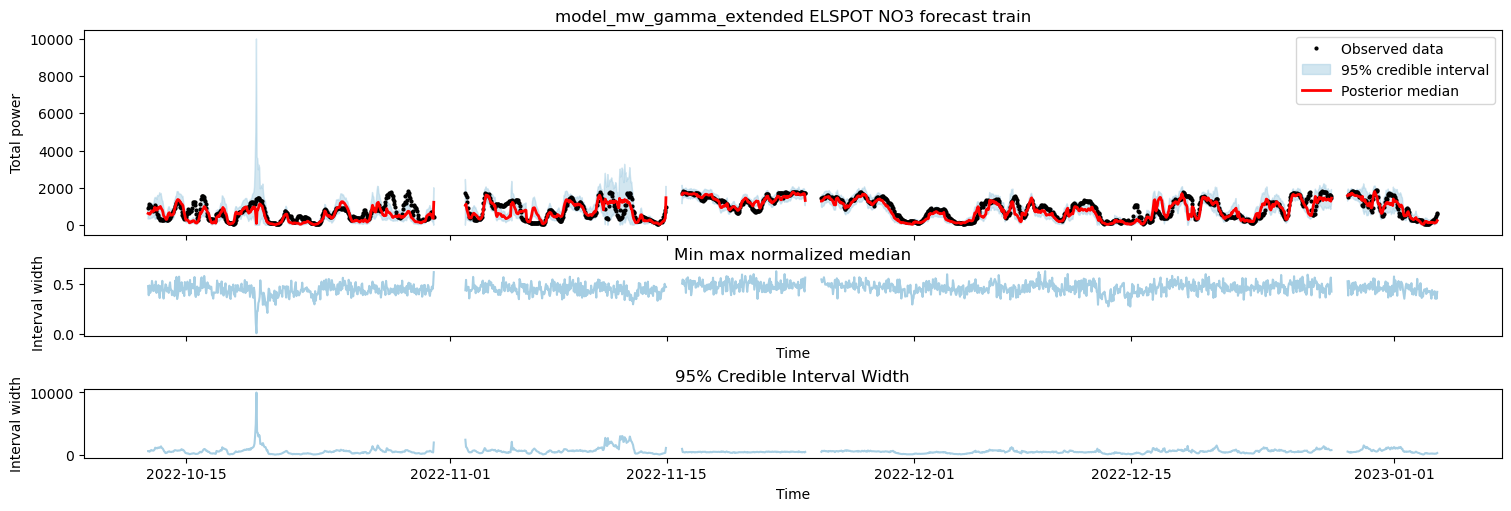

In [17]:
if model_cfg.backend == "numpyro":
    (
        metrics_train,
        y_pred_train,
        predictive_train,
        median_train,
        percentiles_train,
        hdis_train,
    ) = evaluate_numpyro_on_train_set(
        model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
    )
    # Plot

    fig, axes = plot_qr_hdi_prediction(
        Y_true=data["Y_train_gen"],
        conf_interval=hdis_train.T,  # hdi_list[0].T,
        medians=median_train,  # median_list[0],
        n_plot=2000,
        title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} train",
        timestamps=data["X_train_timestamps"],
    )
    plt.show()

In [18]:
timestamps = pd.date_range(
    data["X_test_timestamps"][0], data["X_test_timestamps"][-1], freq="h"
)

In [19]:
df = pd.DataFrame(
    np.stack(
        [data["Y_test_gen"], hdi_list[0].T[:, 0], hdi_list[0].T[:, 1], median_list[0]]
    ).T,
    index=data["X_test_timestamps"],
    columns=["Y_true", "hdi_lower", "hdi_upper", "median"],
)
full_index = pd.date_range(df.index.min(), df.index.max(), freq="h")

# Reindex and fill missing timestamps with NaN
df_full = df.reindex(full_index)

In [20]:
data["feature_cols"]

['air_pressure_at_sea_level',
 'air_temperature_2m',
 'hour_x',
 'hour_y',
 'relative_humidity_2m',
 'wind_direction_10m_x',
 'wind_direction_10m_y',
 'wind_speed_10m',
 'wind_speed_10m+1',
 'wind_speed_10m-1']

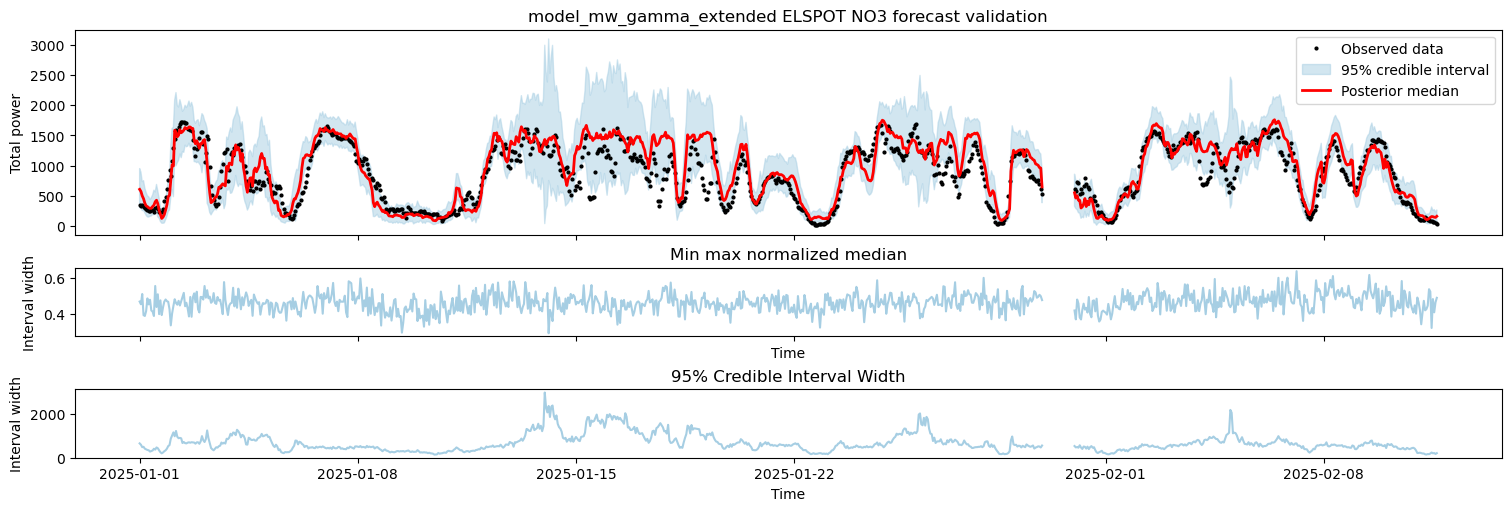

In [21]:
# Plot

fig, axes = plot_qr_hdi_prediction(
    Y_true=data["Y_test_gen"] * max_scaling,
    conf_interval=hdi_list[0].T,
    medians=median_list[0],
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} validation",
    timestamps=data["X_test_timestamps"],
)
plt.show()

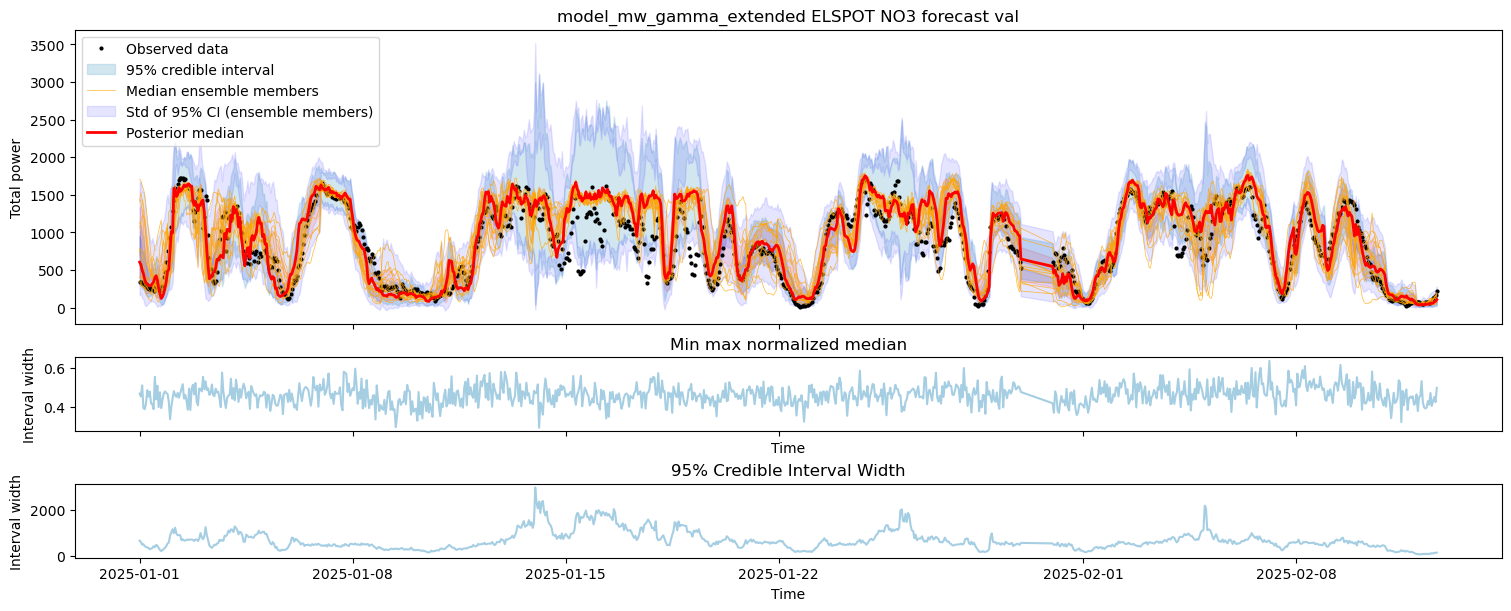

In [22]:
fig, axes = plot_qr_hdi_prediction_ensemble(
    Y_true=data["Y_test_gen"] * max_scaling,
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

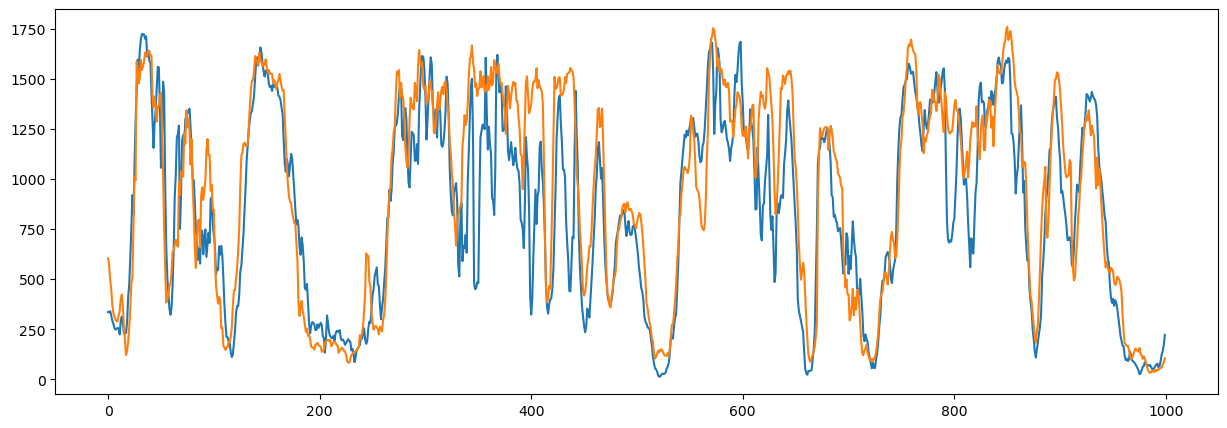

In [23]:
plt.figure(figsize=(15, 5))
plt.plot(data["Y_test_gen"][:1000] * max_scaling)
plt.plot(median_list[0][:1000])

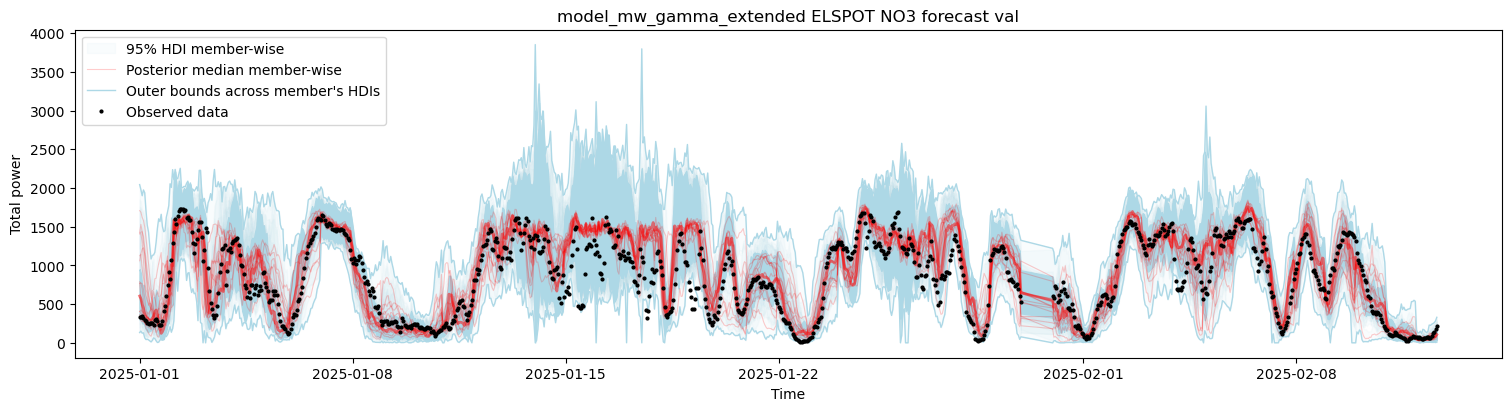

In [24]:
fig, axes = plot_qr_hdi_prediction_ensemble_outline(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

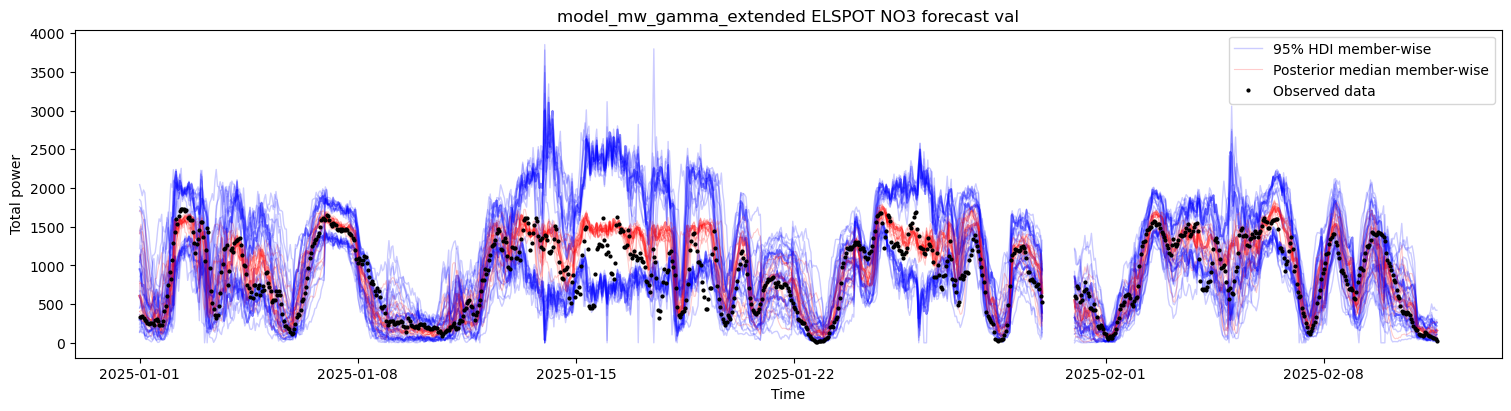

In [25]:
fig, axes = plot_qr_hdi_prediction_ensemble_std(
    Y_true=data["Y_test_gen"],
    ensemble_results=ensemble_results,
    n_plot=1000,
    title=f"{model_cfg.name} {model_cfg.data.bid_zone} {data_cfg.dataset} val",
    timestamps=data["X_test_timestamps"],
)
plt.show()

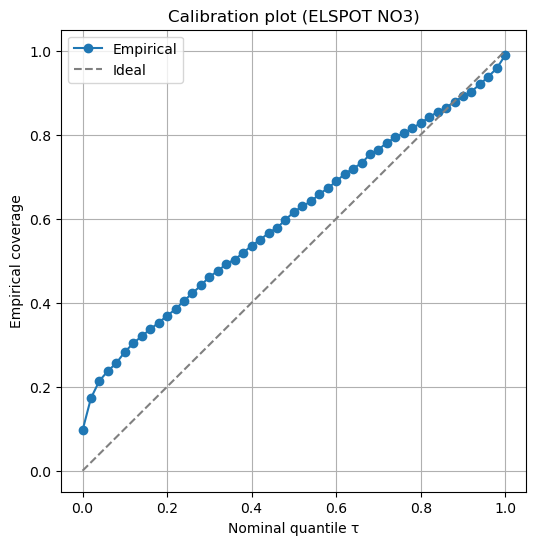

In [26]:
# y_pred: (S, N)

quantiles = torch.linspace(0, 1, 51)
emp_cov = plot_quantile_calibration(
    Y_pred_quantiles=(
        np.quantile(y_pred_list[0], quantiles, axis=0).T
        if model_cfg.backend == "numpyro"
        else y_pred
    ),
    Y_true=(
        data["Y_test_gen"] * max_scaling
        if model_cfg.params.target == "gen"
        else data["Y_test_cf"]
    ),
    quantiles=quantiles,
    bz=model_cfg.data.bid_zone,
)

skew: -0.819922


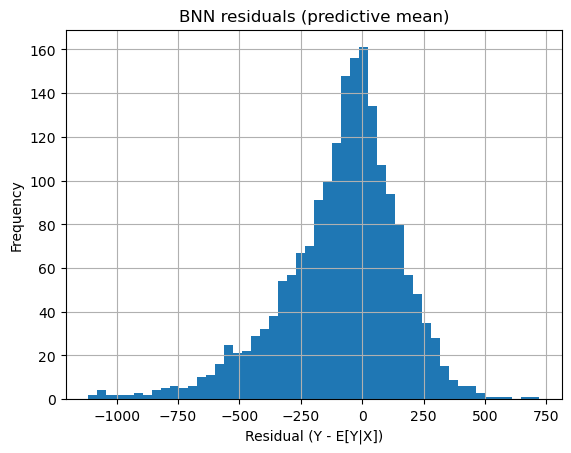

array([-267.77887, -235.39554, -155.97833, ...,  290.55304,  721.7792 ,
        592.0818 ], shape=(1895,), dtype=float32)

In [27]:
plot_residuals(
    median_list[0] * max_scaling,
    data["Y_test_gen"],
)

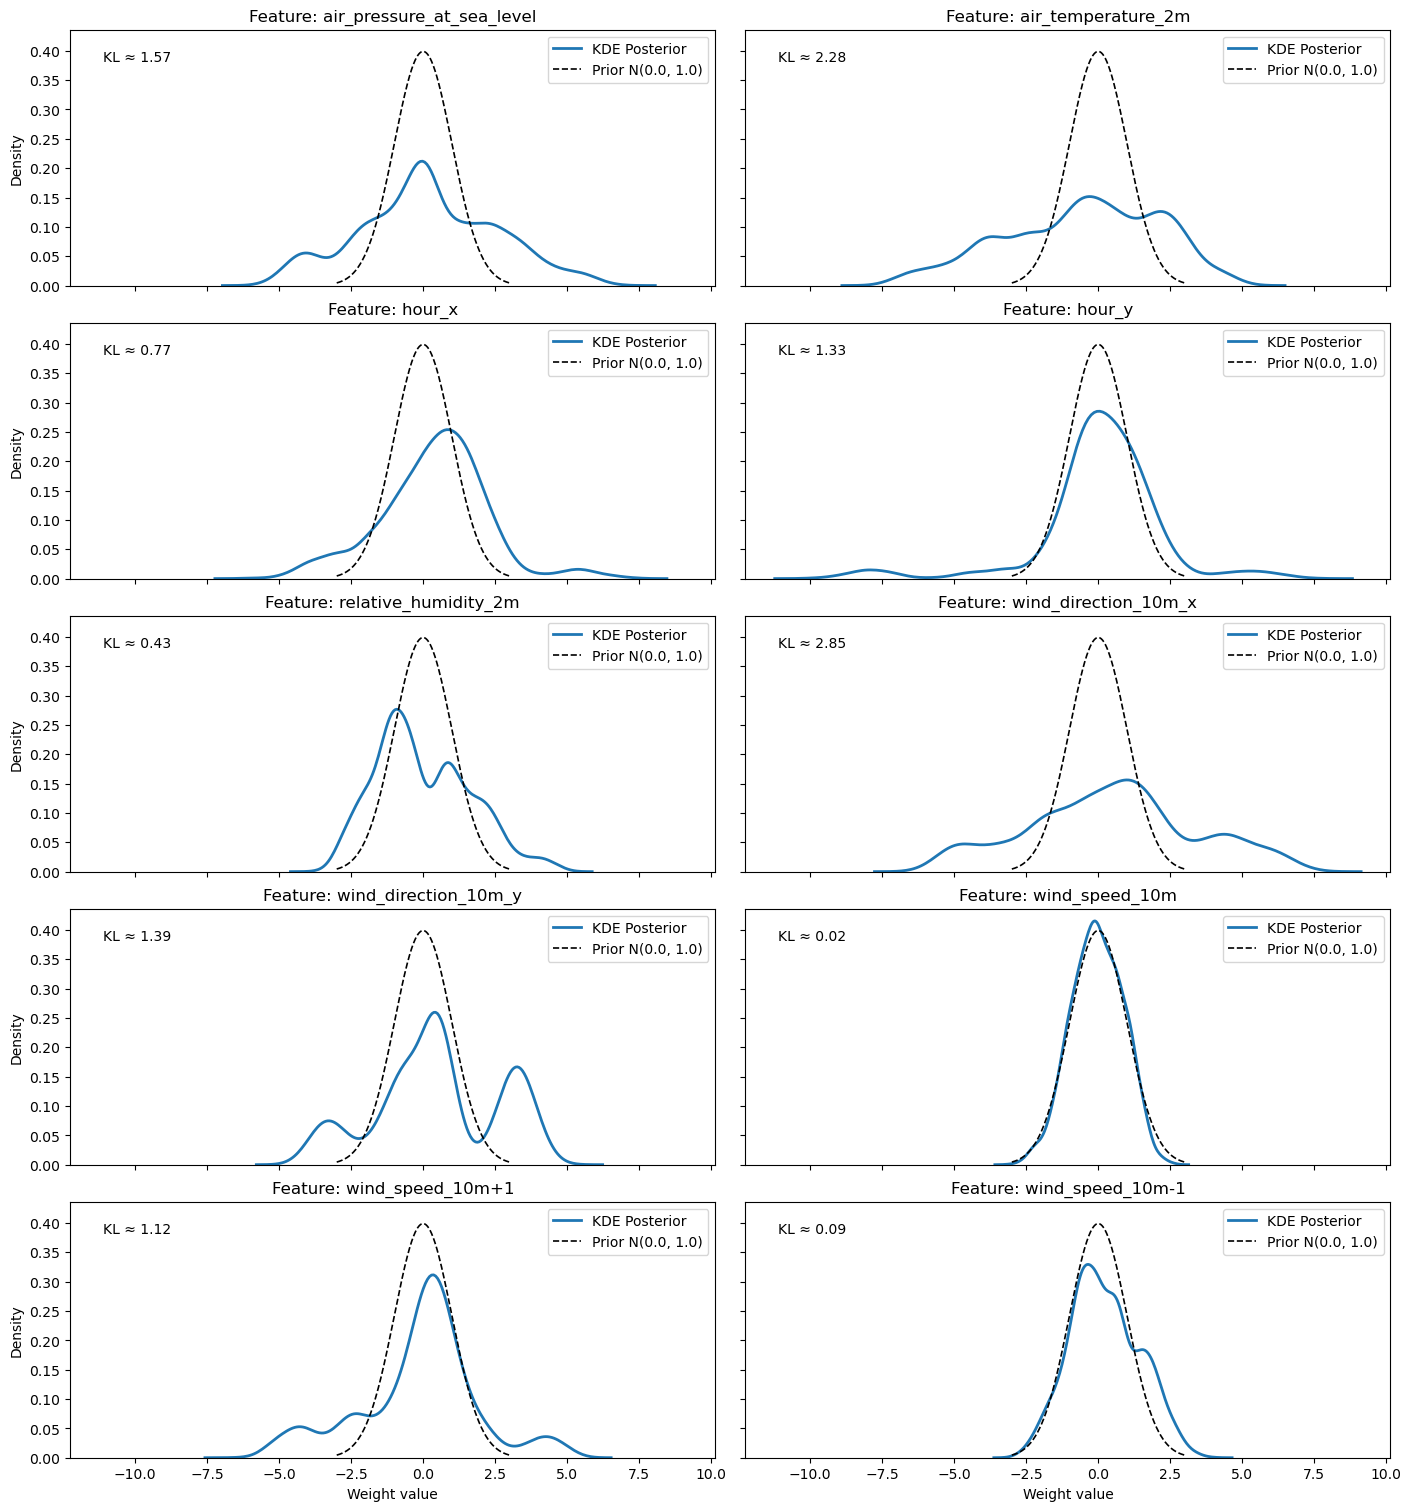

In [28]:
if model_cfg.backend == "numpyro":
    plot_first_layer_feature_posteriors(checkpoint["samples"], data)

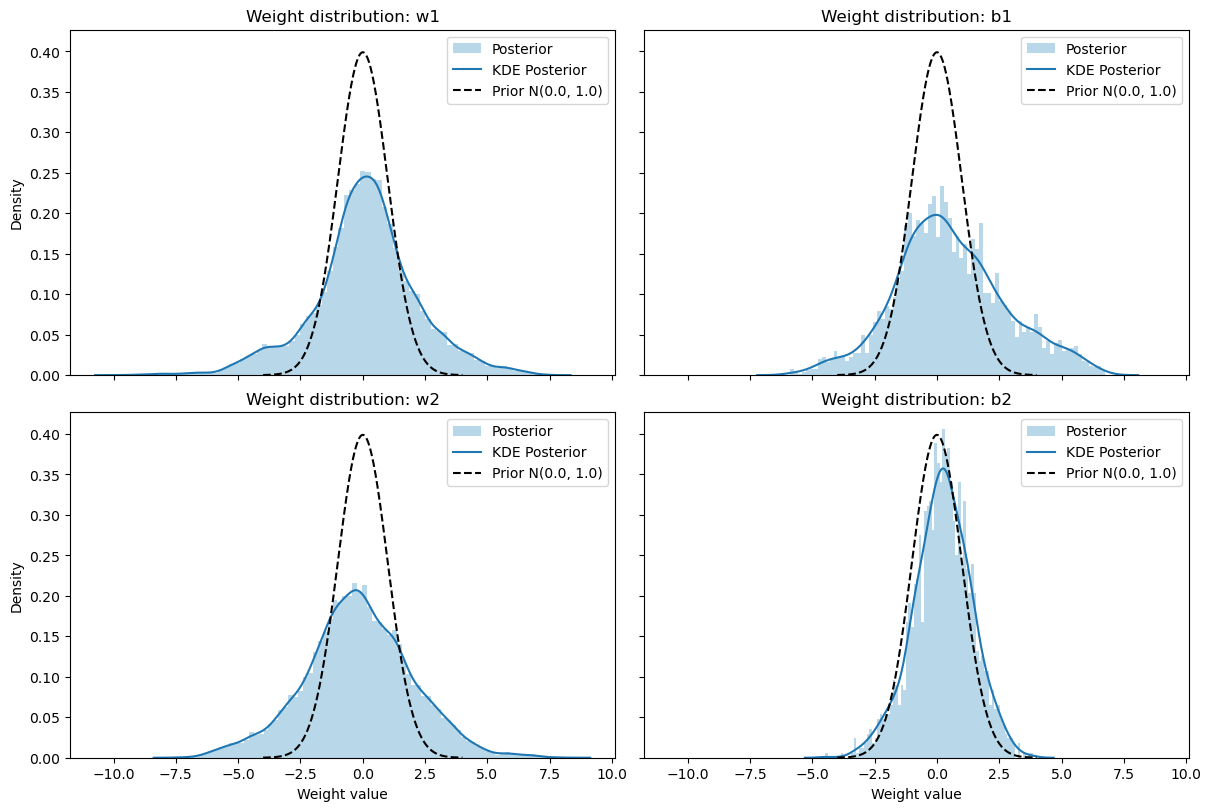

In [29]:
if model_cfg.backend == "numpyro":
    plot_bnn_weight_posteriors(checkpoint["samples"])

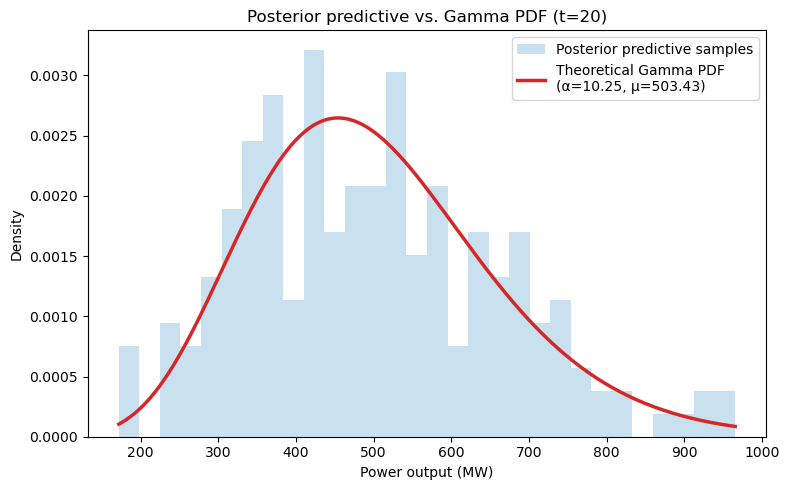

In [30]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_vs_likelihood(
        predictive=predictive,
        model_name=model_cfg.name,
        t=20,
    )

Y not none


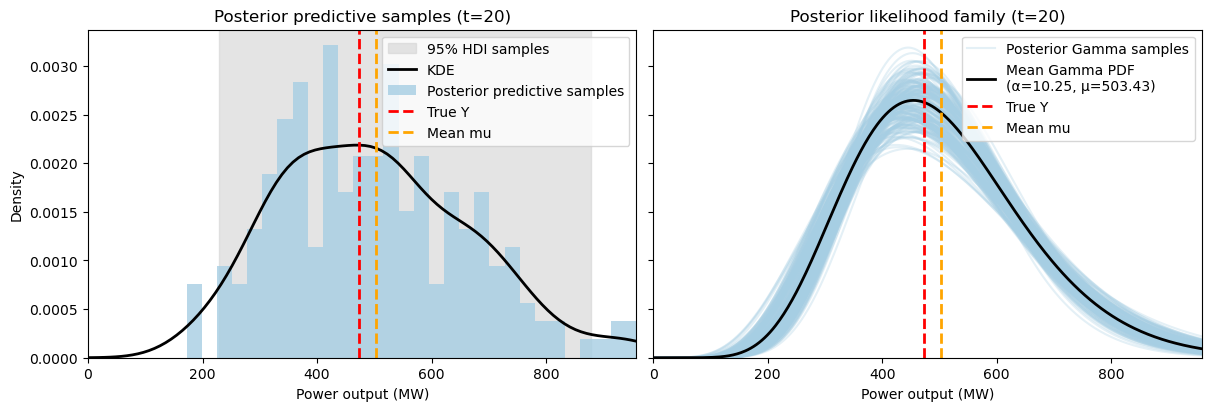

In [31]:
if model_cfg.backend == "numpyro":
    plot_posterior_predictive_family(predictive, model_cfg, data, t=20, hdi=percentiles)

    # Epistemic uncertainty on the left: different outputs for the different model realizations
    # Aleatoric uncertainty on the right: different gamma distribution, each realization's variance informs about it's aleatoric uncertainty
    # TODO: does it make sense to take the mean of the parameters, so say something about its average aleatoric uncertainty?

In [32]:
if model_cfg.backend == "torch":
    plt.figure(figsize=(8, 5))
    plt.plot(checkpoint["losses"][::25], label="Training Loss")
    plt.xlabel("Step")
    plt.ylabel("MSE Loss")
    plt.title("Training Loss Over Time")
    plt.legend()
    plt.grid(True)
    plt.show()

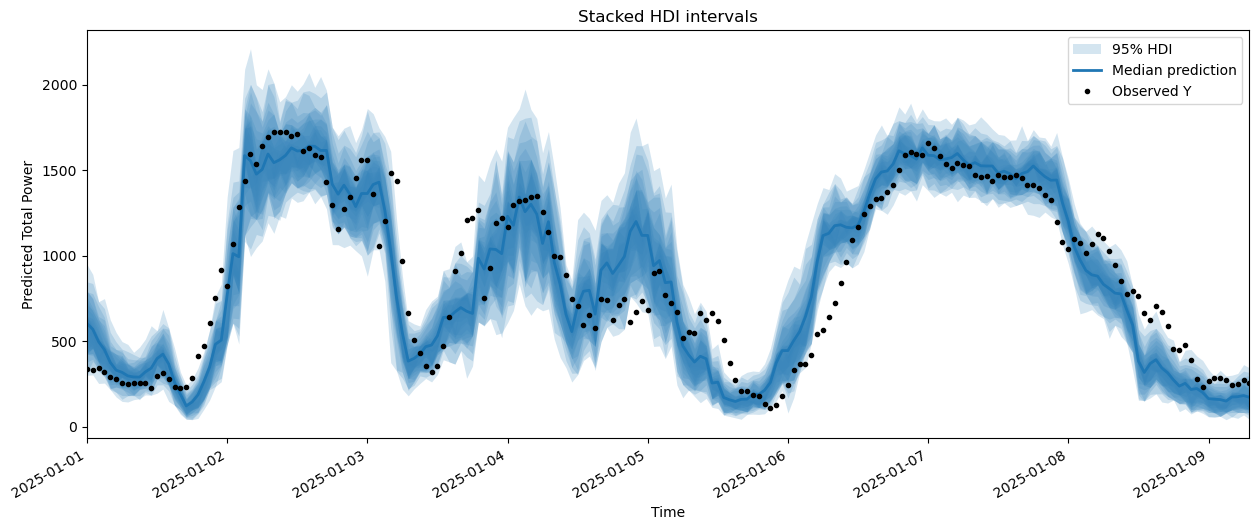

In [33]:
if model_cfg.backend == "numpyro":
    plot_stacked_hdi_intervals(
        preds=y_pred_list[0],
        Y_true=data["Y_test_gen"],
        n_plot=200,
        timestamps=data["X_test_timestamps"],
    )

PIT mean: 0.4007 (should be ~1 if calibrated)


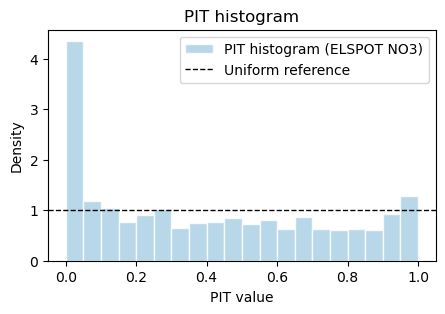

In [34]:
if model_cfg.backend == "numpyro":
    pits = plot_pit_histogram(
        preds=y_pred_list[0], Y_true=data["Y_test_gen"], bz=model_cfg.data.bid_zone
    )

In [35]:
if model_cfg.backend == "torch" and len(data["X_train"].shape) == 4:
    evaluate_and_plot_qr_ensemble_medians(
        model=model,
        data=data,
        quantiles=quantiles,
        n_members=15,
        n_plot=1000,
    )

Compare learned weights for aggregation and max capacity of parks


In [36]:
import torch

if model_cfg.backend == "numpyro":
    agg_logits = samples["agg_logits"].mean(0)
elif model_cfg.backend == "torch":
    agg_logits = torch.softmax(checkpoint["model_state_dict"]["agg_logits"], dim=0)

print(
    "Max capacity wind parks: ",
    torch.softmax(torch.tensor(data["sites_meta"]), 0).reshape([-1]),
)
print("Learned weightings wind parks: ", agg_logits)

Max capacity wind parks:  tensor([0.0141, 0.0335, 0.0143, 0.0805, 0.1022, 0.0433, 0.0100, 0.0371, 0.0127,
        0.0513, 0.0135, 0.0350, 0.0128, 0.0089, 0.0084, 0.0066, 0.0075, 0.0525,
        0.0217, 0.3691, 0.0394, 0.0074, 0.0073, 0.0108], dtype=torch.float64)
Learned weightings wind parks:  [0.01894377 0.00860922 0.02066445 0.1393047  0.07840507 0.00908769
 0.00364486 0.07230699 0.05702806 0.06186992 0.00449379 0.05221932
 0.00875258 0.01487914 0.01136475 0.01494164 0.06568019 0.04536321
 0.08058838 0.09324327 0.10927305 0.00379374 0.01017741 0.01536478]


Max capacity wind parks:  tensor([0.0141, 0.0335, 0.0143, 0.0805, 0.1022, 0.0433, 0.0100, 0.0371, 0.0127,
        0.0513, 0.0135, 0.0350, 0.0128, 0.0089, 0.0084, 0.0066, 0.0075, 0.0525,
        0.0217, 0.3691, 0.0394, 0.0074, 0.0073, 0.0108], dtype=torch.float64)
Learned weightings wind parks:  [0.01894377 0.00860922 0.02066445 0.1393047  0.07840507 0.00908769
 0.00364486 0.07230699 0.05702806 0.06186992 0.00449379 0.05221932
 0.00875258 0.01487914 0.01136475 0.01494164 0.06568019 0.04536321
 0.08058838 0.09324327 0.10927305 0.00379374 0.01017741 0.01536478]


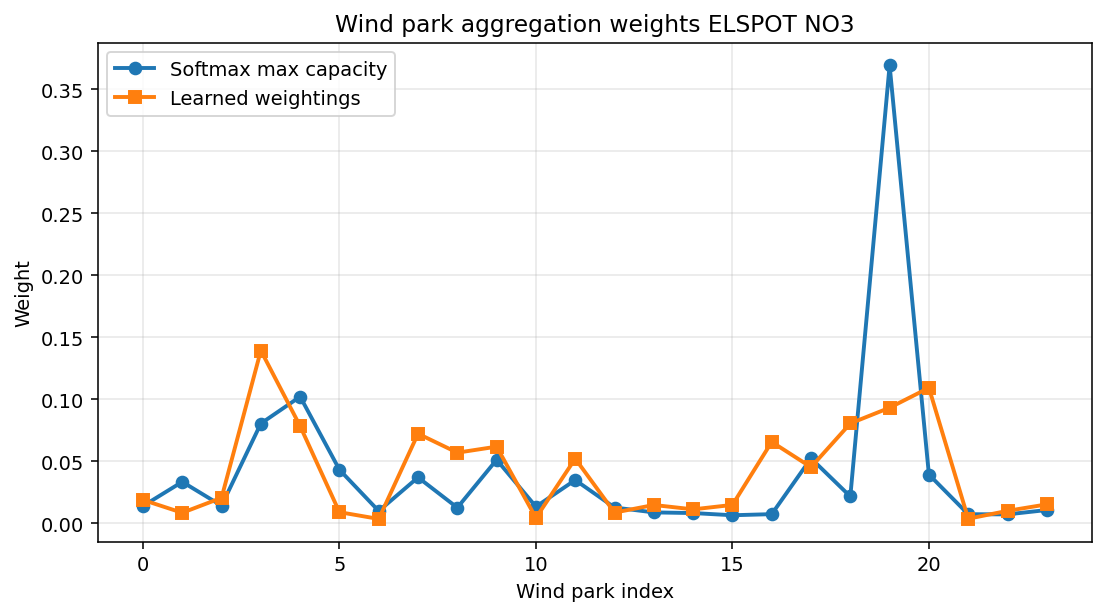

In [37]:
softmax_caps = torch.softmax(torch.tensor(data["sites_meta"]), 0).numpy()
learned_weights = (
    samples["agg_logits"].mean(0)
    if model_cfg.backend == "numpyro"
    else torch.softmax(checkpoint["model_state_dict"]["agg_logits"], dim=0)
)

print(
    "Max capacity wind parks: ",
    torch.softmax(torch.tensor(data["sites_meta"]), 0).reshape([-1]),
)
print("Learned weightings wind parks: ", learned_weights)
x = np.arange(len(softmax_caps))

fig, ax = plt.subplots(figsize=(8, 4.5), dpi=140)

ax.plot(
    x,
    softmax_caps,
    marker="o",
    lw=2,
    label="Softmax max capacity",
)

ax.plot(
    x,
    learned_weights,
    marker="s",
    lw=2,
    label="Learned weightings",
)

ax.set_xlabel("Wind park index")
ax.set_ylabel("Weight")
ax.set_title("Wind park aggregation weights " + model_cfg.data.bid_zone)

ax.grid(alpha=0.3)
ax.legend()

plt.tight_layout()
plt.show()

In [78]:
import importlib
import training.evaluate as load_eval

importlib.reload(load_eval)
from training.evaluate import evaluate_numpyro_on_train_set

In [71]:
import copy

data_copy = copy.deepcopy(data)

length = len(data_copy["X_train"])

In [83]:
window_size = 1080

metrics_train_list = []


for start in range(0, length - window_size + 1, window_size):
    print(start)
    end = start + window_size

    data["X_train"] = data_copy["X_train"][start:end]
    data["Y_train_gen"] = data_copy["Y_train_gen"][start:end]
    (
        metrics_train,
        y_pred_train,
        predictive_train,
        median_train,
        percentiles_train,
        hdis_train,
    ) = evaluate_numpyro_on_train_set(
        model, checkpoint["samples"], checkpoint["rng_key_predict"], data, model_cfg
    )

    metrics_train_list.append(metrics_train)

0
(1080, 24, 10) (1080,)
(200, 1080)
1080
(1080, 24, 10) (1080,)
(200, 1080)
2160
(1080, 24, 10) (1080,)
(200, 1080)
3240
(1080, 24, 10) (1080,)
(200, 1080)
4320
(1080, 24, 10) (1080,)
(200, 1080)
5400
(1080, 24, 10) (1080,)
(200, 1080)
6480
(1080, 24, 10) (1080,)
(200, 1080)
7560
(1080, 24, 10) (1080,)
(200, 1080)
8640
(1080, 24, 10) (1080,)
(200, 1080)
9720
(1080, 24, 10) (1080,)
(200, 1080)
10800
(1080, 24, 10) (1080,)
(200, 1080)
11880
(1080, 24, 10) (1080,)
(200, 1080)
12960
(1080, 24, 10) (1080,)
(200, 1080)
14040
(1080, 24, 10) (1080,)
(200, 1080)
15120
(1080, 24, 10) (1080,)
(200, 1080)
16200
(1080, 24, 10) (1080,)
(200, 1080)


In [84]:
rmse_vals = np.array([d["rmse_median"] for d in metrics_train_list])
crps_vals = np.array([d["crps"] for d in metrics_train_list])


def summarize(x):
    return {
        "mean": np.mean(x),
        "std": np.std(x),
        "min": np.min(x),
        "max": np.max(x),
        "range": np.max(x) - np.min(x),
    }


print("RMSE:", summarize(rmse_vals))
print("CRPS:", summarize(crps_vals))

RMSE: {'mean': np.float32(244.59647), 'std': np.float32(47.647762), 'min': np.float32(163.14676), 'max': np.float32(321.343), 'range': np.float32(158.19623)}
CRPS: {'mean': np.float64(130.53264987109705), 'std': np.float64(30.523223289934432), 'min': np.float64(72.85203072702382), 'max': np.float64(174.42221762820282), 'range': np.float64(101.570186901179)}


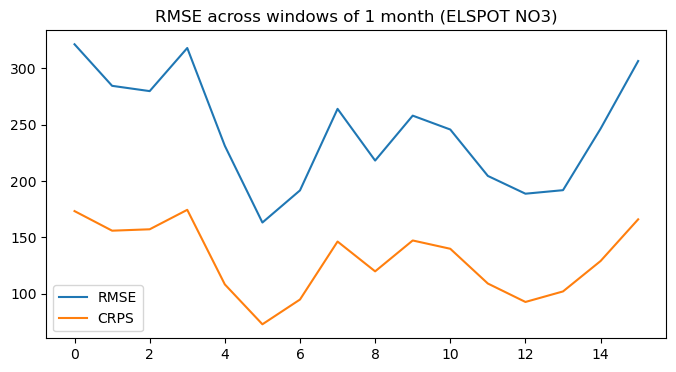

In [85]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.plot(rmse_vals, label="RMSE")
plt.plot(crps_vals, label="CRPS")
plt.legend()
plt.title(f"RMSE across windows of 1 month ({model_cfg.data.bid_zone})")
plt.show()

In [86]:
print("Worst RMSE window:", np.argmax(rmse_vals))
print("Worst CRPS window:", np.argmax(crps_vals))

print("Best RMSE window:", np.argmin(rmse_vals))
print("Best CRPS window:", np.argmin(crps_vals))

Worst RMSE window: 0
Worst CRPS window: 3
Best RMSE window: 5
Best CRPS window: 5


In [91]:
idx_rmse = np.argmin(np.abs(rmse_vals - np.mean(rmse_vals)))
idx_crps = np.argmin(np.abs(crps_vals - np.mean(crps_vals)))
print(idx_rmse, idx_crps)

10 14
